# K-Fold Cross Validation

## How k-fold cross-validation works

**k-fold cross-validation is an evaluation method**, not a predictive model. A single train/validation split can give a misleading impression of performance if the split happens to be unusually easy or difficult. Cross-validation evaluates the same learning procedure across several splits to estimate how well it generalizes to unseen data.

### The procedure

1. Keep a separate test set for the final evaluation. Divide the remaining training data into $k$ approximately equal, non-overlapping folds.
2. Train a fresh model on $k-1$ folds and evaluate it on the remaining fold.
3. Repeat $k$ times, changing the held-out fold so that every example is used for validation exactly once.
4. Summarize the validation scores; when model choices are settled, fit a final model on all training data.

If $a_j$ is the accuracy on fold $j$, the mean accuracy is $\bar{a} = \frac{1}{k} \sum_{j=1}^{k} a_j$. The population standard deviation reported by `accuracies.std()` is $\sigma = \sqrt{\frac{1}{k} \sum_{j=1}^{k}(a_j - \bar{a})^2}$

The mean summarizes predictive performance, while the standard deviation describes sensitivity to the chosen folds. It is **not a confidence interval**: fold scores are not independent because their training sets overlap.

### In this notebook

`cross_val_score` evaluates an RBF support vector classifier with `cv=10`. Each fit uses about 90% of `X_train` for training and 10% for validation, without using `X_test`. For this classifier and an integer `cv`, scikit-learn uses stratified folds, preserving class proportions approximately, without shuffling by default. It clones and refits the estimator for each fold; it does not reuse the already fitted model or return a final fitted model.

### Choosing folds safely

- Common choices are $k=5$ or $k=10$. Larger $k$ leaves more data for each training fit but increases computation and does not guarantee a more stable estimate.
- Learn scaling, imputation, and feature selection only from each fold's training portion, typically using a `Pipeline`. The simplified code below scales before cross-validation, so its fold scores can be affected by preprocessing leakage.
- Ordinary folds assume examples are sufficiently independent. Use group-aware splits for repeated subjects and time-aware splits for chronological data.
- Use a metric suited to the problem; accuracy can hide poor minority-class performance. If cross-validation guides hyperparameter choices, reserve the test set for the final assessment.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Importing the dataset

In [2]:
dataset = pd.read_csv('../data/Social_Network_Ads.csv')
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

## Splitting the dataset into the Training set and Test set

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)

## Feature Scaling

In [4]:
from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

## Training the Kernel SVM model on the Training set

In [5]:
from sklearn.svm import SVC

classifier = SVC(kernel='rbf', random_state=0)
classifier.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",0
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


## Making the Confusion Matrix

In [6]:
from sklearn.metrics import confusion_matrix, accuracy_score

y_pred = classifier.predict(X_test)
cm = confusion_matrix(y_test, y_pred)
print(cm)
accuracy_score(y_test, y_pred)

[[64  4]
 [ 3 29]]


0.93

## Applying k-Fold Cross Validation

In [7]:
from sklearn.model_selection import cross_val_score

accuracies = cross_val_score(estimator=classifier, X=X_train, y=y_train, cv=10)
print("Accuracy: {:.2f} %".format(accuracies.mean() * 100))
print("Standard Deviation: {:.2f} %".format(accuracies.std() * 100))

Accuracy: 90.33 %
Standard Deviation: 6.57 %


## Visualising the Training set results

/var/folders/67/rb5f60691h95fqyf4bx2bzlr0000gn/T/ipykernel_69881/1284924610.py:25: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


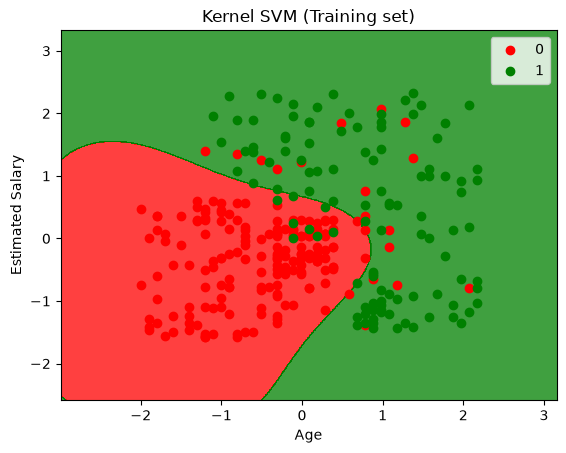

In [8]:
from matplotlib.colors import ListedColormap

X_set, y_set = X_train, y_train
X1, X2 = np.meshgrid(
    np.arange(
        start=X_set[:, 0].min() - 1,
        stop=X_set[:, 0].max() + 1,
        step=0.01
    ),
    np.arange(
        start=X_set[:, 1].min() - 1,
        stop=X_set[:, 1].max() + 1,
        step=0.01
    ))
plt.contourf(
    X1,
    X2,
    classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
    alpha=0.75,
    cmap=ListedColormap(('red', 'green'))
)
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(
        X_set[y_set == j, 0],
        X_set[y_set == j, 1],
        c=ListedColormap(('red', 'green'))(i),
        label=j)
plt.title('Kernel SVM (Training set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()

## Visualising the Test set results

/var/folders/67/rb5f60691h95fqyf4bx2bzlr0000gn/T/ipykernel_69881/2731957278.py:23: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(


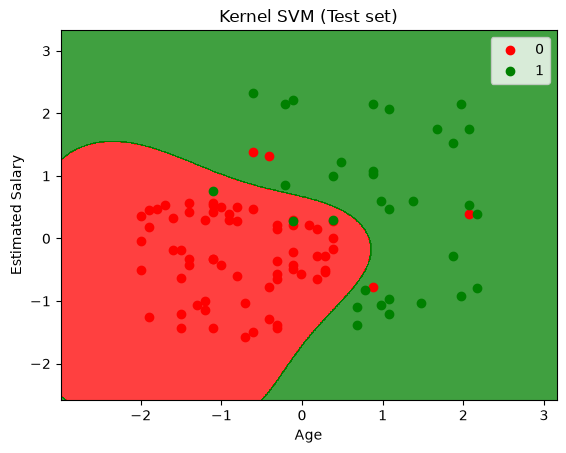

In [9]:
from matplotlib.colors import ListedColormap

X_set, y_set = X_test, y_test
X_set, y_set = X_test, y_test
X1, X2 = np.meshgrid(
    np.arange(
        start=X_set[:, 0].min() - 1,
        stop=X_set[:, 0].max() + 1,
        step=0.01
    ), np.arange(
        start=X_set[:, 1].min() - 1,
        stop=X_set[:, 1].max() + 1,
        step=0.01
    ))
plt.contourf(X1,
             X2,
             classifier.predict(np.array([X1.ravel(), X2.ravel()]).T).reshape(X1.shape),
             alpha=0.75,
             cmap=ListedColormap(('red', 'green')))
plt.xlim(X1.min(), X1.max())
plt.ylim(X2.min(), X2.max())
for i, j in enumerate(np.unique(y_set)):
    plt.scatter(
        X_set[y_set == j, 0],
        X_set[y_set == j, 1],
        c=ListedColormap(('red', 'green'))(i),
        label=j)
plt.title('Kernel SVM (Test set)')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.legend()
plt.show()